In [21]:
#merged_glory_chla_colocated_100.nc

import xarray as xr

# Read NetCDF file
ds = xr.open_dataset("merged_glory_chla_colocated_100.nc")

# Display dataset information
print(ds)

<xarray.Dataset> Size: 6GB
Dimensions:      (time: 339, latitude: 337, longitude: 661)
Coordinates:
  * latitude     (latitude) float32 1kB 0.0 0.08333 0.1667 ... 27.83 27.92 28.0
  * longitude    (longitude) float32 3kB 45.0 45.08 45.17 ... 99.83 99.92 100.0
  * time         (time) datetime64[ns] 3kB 1997-10-01 1997-11-01 ... 2025-12-01
Data variables:
    zos          (time, latitude, longitude) float64 604MB ...
    so           (time, latitude, longitude) float64 604MB ...
    thetao       (time, latitude, longitude) float64 604MB ...
    uo           (time, latitude, longitude) float64 604MB ...
    vo           (time, latitude, longitude) float64 604MB ...
    mlotst       (time, latitude, longitude) float64 604MB ...
    vorticity    (time, latitude, longitude) float64 604MB ...
    okubo_weiss  (time, latitude, longitude) float64 604MB ...
    grad_ssh     (time, latitude, longitude) float64 604MB ...
    chlor_a      (time, latitude, longitude) float32 302MB ...
Attributes:
  

In [22]:
import xarray as xr
import numpy as np
import pandas as pd
import joblib

In [23]:
# ============================================================
# Load Merged Dataset
# ============================================================

ds = xr.open_dataset("merged_glory_chla_colocated_100.nc")

print(ds)

<xarray.Dataset> Size: 6GB
Dimensions:      (time: 339, latitude: 337, longitude: 661)
Coordinates:
  * latitude     (latitude) float32 1kB 0.0 0.08333 0.1667 ... 27.83 27.92 28.0
  * longitude    (longitude) float32 3kB 45.0 45.08 45.17 ... 99.83 99.92 100.0
  * time         (time) datetime64[ns] 3kB 1997-10-01 1997-11-01 ... 2025-12-01
Data variables:
    zos          (time, latitude, longitude) float64 604MB ...
    so           (time, latitude, longitude) float64 604MB ...
    thetao       (time, latitude, longitude) float64 604MB ...
    uo           (time, latitude, longitude) float64 604MB ...
    vo           (time, latitude, longitude) float64 604MB ...
    mlotst       (time, latitude, longitude) float64 604MB ...
    vorticity    (time, latitude, longitude) float64 604MB ...
    okubo_weiss  (time, latitude, longitude) float64 604MB ...
    grad_ssh     (time, latitude, longitude) float64 604MB ...
    chlor_a      (time, latitude, longitude) float32 302MB ...
Attributes:
  

In [24]:
# ============================================================
#  East Arabian Sea Region
# ============================================================

ds = ds.sel(
    latitude=slice(5, 28),     
    longitude=slice(65, 78)
)

print(ds)


print(ds.latitude.min().values)
print(ds.latitude.max().values)

print(ds.longitude.min().values)
print(ds.longitude.max().values)

<xarray.Dataset> Size: 1GB
Dimensions:      (time: 339, latitude: 277, longitude: 157)
Coordinates:
  * latitude     (latitude) float32 1kB 5.0 5.083 5.167 ... 27.83 27.92 28.0
  * longitude    (longitude) float32 628B 65.0 65.08 65.17 ... 77.83 77.92 78.0
  * time         (time) datetime64[ns] 3kB 1997-10-01 1997-11-01 ... 2025-12-01
Data variables:
    zos          (time, latitude, longitude) float64 118MB ...
    so           (time, latitude, longitude) float64 118MB ...
    thetao       (time, latitude, longitude) float64 118MB ...
    uo           (time, latitude, longitude) float64 118MB ...
    vo           (time, latitude, longitude) float64 118MB ...
    mlotst       (time, latitude, longitude) float64 118MB ...
    vorticity    (time, latitude, longitude) float64 118MB ...
    okubo_weiss  (time, latitude, longitude) float64 118MB ...
    grad_ssh     (time, latitude, longitude) float64 118MB ...
    chlor_a      (time, latitude, longitude) float32 59MB ...
Attributes:
    hi

In [25]:
# ============================================================
# Select 2025
# ============================================================

ds_2025 = ds.sel(
    time=slice(
        "2025-01-01",
        "2025-12-01"
    )
)

print(ds_2025)
print(ds_2025.time.values)

<xarray.Dataset> Size: 40MB
Dimensions:      (time: 12, latitude: 277, longitude: 157)
Coordinates:
  * latitude     (latitude) float32 1kB 5.0 5.083 5.167 ... 27.83 27.92 28.0
  * longitude    (longitude) float32 628B 65.0 65.08 65.17 ... 77.83 77.92 78.0
  * time         (time) datetime64[ns] 96B 2025-01-01 2025-02-01 ... 2025-12-01
Data variables:
    zos          (time, latitude, longitude) float64 4MB ...
    so           (time, latitude, longitude) float64 4MB ...
    thetao       (time, latitude, longitude) float64 4MB ...
    uo           (time, latitude, longitude) float64 4MB ...
    vo           (time, latitude, longitude) float64 4MB ...
    mlotst       (time, latitude, longitude) float64 4MB ...
    vorticity    (time, latitude, longitude) float64 4MB ...
    okubo_weiss  (time, latitude, longitude) float64 4MB ...
    grad_ssh     (time, latitude, longitude) float64 4MB ...
    chlor_a      (time, latitude, longitude) float32 2MB ...
Attributes:
    history:             

In [26]:
# ============================================================
# Log10 Chlorophyll
# ============================================================

ds_2025["chlor_a_log10"] = xr.where(
    ds_2025["chlor_a"] > 0,
    np.log10(ds_2025["chlor_a"]),
    np.nan
)


# ============================================================
# Natural Log MLD
# ============================================================

ds_2025["mlotst_ln"] = xr.where(
    ds_2025["mlotst"] > 0,
    np.log(ds_2025["mlotst"]),
    np.nan
)

In [27]:
# ============================================================
# Month Feature
# ============================================================

month = ds_2025.time.dt.month

# ============================================================
# Cyclic Month Features
# ============================================================

ds_2025["month_sin"] = xr.DataArray(
    np.sin(2*np.pi*month/12),
    coords={"time": ds_2025.time},
    dims=["time"]
)

ds_2025["month_cos"] = xr.DataArray(
    np.cos(2*np.pi*month/12),
    coords={"time": ds_2025.time},
    dims=["time"]
)

In [28]:
# ============================================================
# Expand Month Features
# ============================================================

month_sin_3d = ds_2025["month_sin"].broadcast_like(ds_2025["zos"])

month_cos_3d = ds_2025["month_cos"].broadcast_like(ds_2025["zos"])

In [29]:
# ============================================================
# Feature Stack
# ============================================================

feature_stack = np.stack(
    [
        month_sin_3d.values,
        month_cos_3d.values,
        #ds_2025["zos"].values,
        ds_2025["so"].values,
        ds_2025["thetao"].values,
        ds_2025["uo"].values,
        ds_2025["vo"].values,
        ds_2025["mlotst_ln"].values,
        ds_2025["vorticity"].values,
        ds_2025["okubo_weiss"].values
        #ds_2025["grad_ssh"].values
    ],
    axis=-1
)

print(feature_stack.shape)

(12, 277, 157, 9)


In [30]:
# ============================================================
# Valid Ocean Mask
# ============================================================

valid_mask = np.isfinite(feature_stack).all(axis=-1)

print(valid_mask.shape)

(12, 277, 157)


In [31]:
FEATURES = [
    "month_sin",
    "month_cos",
    #"zos",
    "so",
    "thetao",
    "uo",
    "vo",
    "mlotst_ln",
    "vorticity",
    "okubo_weiss"
    #"grad_ssh"
]

X_pred = pd.DataFrame(
    feature_stack[valid_mask],
    columns=FEATURES
).astype("float32")

In [32]:
UNDER_PENALTY = 0.008

def underestimation_loss(y_true, y_pred):

    error = y_true - y_pred

    under_mask = error > 0

    grad = np.where(
        under_mask,
        -2.0 * (1.0 + UNDER_PENALTY) * error,
        -2.0 * error
    )

    hess = np.where(
        under_mask,
        2.0 * (1.0 + UNDER_PENALTY),
        2.0
    )

    return grad, hess

In [33]:
# ============================================================
# Load Trained XGBoost Model
# ============================================================

import joblib

model = joblib.load(
    "xgboost_EAS_NO_SSH_model.pkl"
)

In [34]:
# ============================================================
# Prediction
# ============================================================

pred_log10 = model.predict(X_pred)

print(pred_log10.shape)

(304656,)


In [35]:
# ============================================================
# Rebuild Grid
# ============================================================

pred_grid_log10 = np.full(
    valid_mask.shape,
    np.nan,
    dtype=np.float32
)

pred_grid_log10[valid_mask] = pred_log10

In [36]:
# ============================================================
# Back Transform
# ============================================================

pred_grid_chl = np.power(
    10,
    pred_grid_log10
)

In [37]:
# ============================================================
# Add Predictions
# ============================================================

ds_2025["chlor_a_pred_log10"] = (
    ("time","latitude","longitude"),
    pred_grid_log10
)

ds_2025["chlor_a_pred"] = (
    ("time","latitude","longitude"),
    pred_grid_chl
)

In [38]:
true_log = ds_2025["chlor_a_log10"]

pred_log = ds_2025["chlor_a_pred_log10"]

In [39]:
# ============================================================
# Error
# ============================================================

ds_2025["prediction_error"] = (
    ds_2025["chlor_a_pred_log10"]
    -
    ds_2025["chlor_a_log10"]
)



In [40]:
import xarray as xr
import xskillscore as xs
import matplotlib.pyplot as plt

/home/prasanna/anaconda3/envs/mlenv/lib/python3.10/site-packages/xskillscore/core/np_deterministic.py:314: RuntimeWarning: invalid value encountered in divide
  r = r_num / r_den


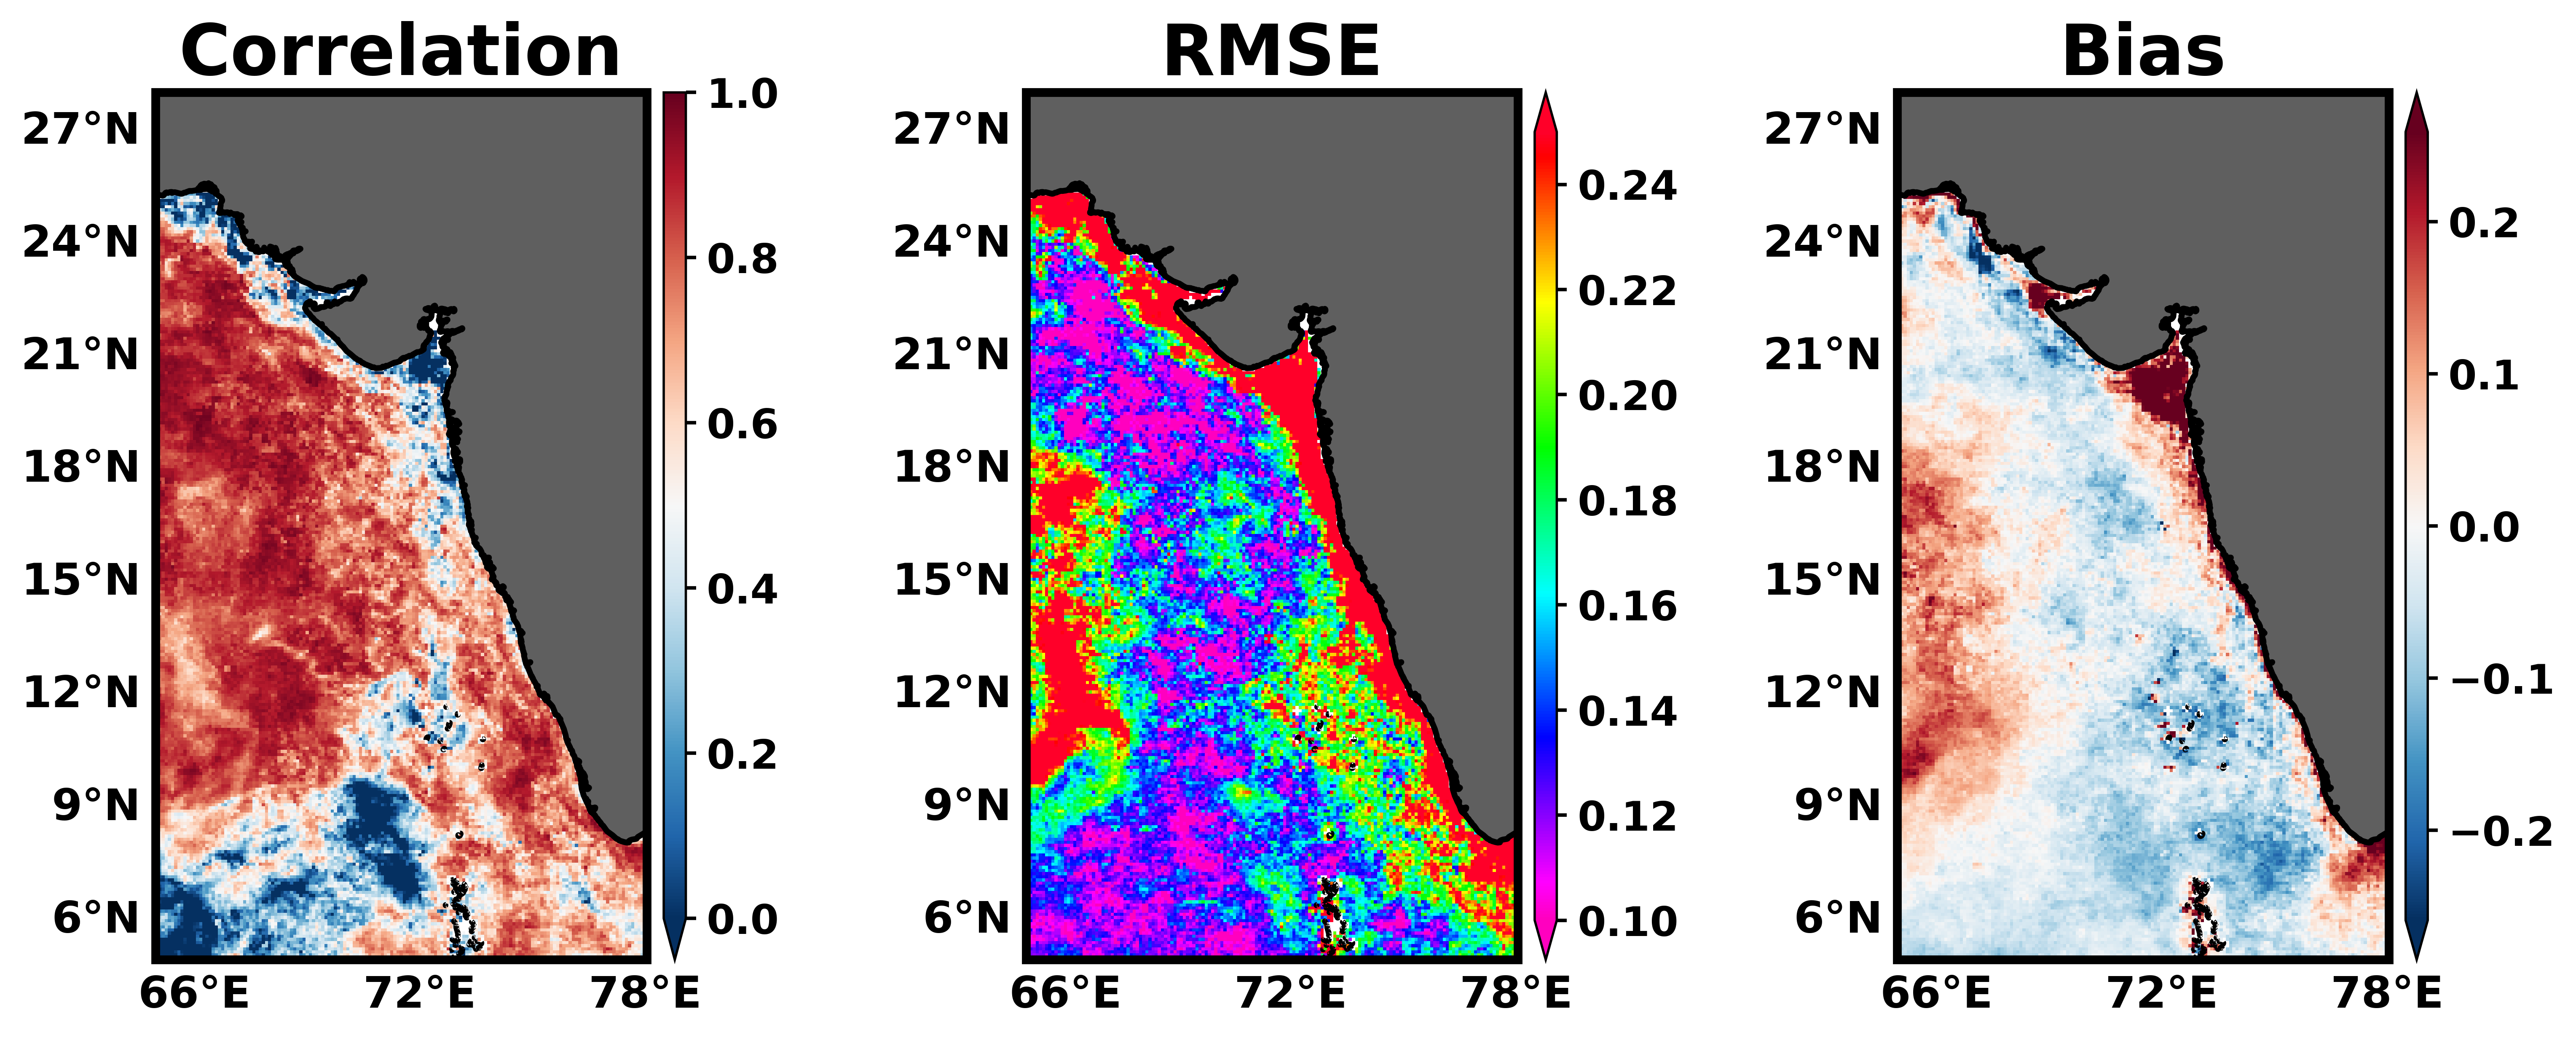

In [41]:
# logged

# ==========================================================
# Spatial Performance Maps
# Correlation | RMSE | Bias
# ==========================================================
from mpl_toolkits.axes_grid1 import make_axes_locatable
import numpy as np
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import xskillscore as xs

# ==========================================================
# Compute Metrics
# ==========================================================


corr_map = xs.pearson_r(
    true_log,
    pred_log,
    dim="time",
    skipna=True
)

rmse_map = xs.rmse(
    true_log,
    pred_log,
    dim="time",
    skipna=True
)

bias_map = xs.me(
    true_log,
    pred_log,
    dim="time",
    skipna=True
)









# ==========================================================
# Global Plot Settings
# ==========================================================

plt.rcParams["font.weight"] = "bold"
plt.rcParams["axes.labelweight"] = "bold"
plt.rcParams["axes.titleweight"] = "bold"

# ==========================================================
# Create Figure
# ==========================================================

fig, ax = plt.subplots(
    nrows=1,
    ncols=3,
    figsize=(12.2,4.9),
    dpi=500,
    subplot_kw={"projection": ccrs.PlateCarree()}
)


# ==========================================================
# Correlation Map
# ==========================================================

corr_plot = corr_map.plot(
    ax=ax[0],
    transform=ccrs.PlateCarree(),
    cmap="RdBu_r",
    vmin=0.0,
    vmax=1,
    robust=True,
    add_colorbar=False,
    
)
divider0 = make_axes_locatable(ax[0])
cax0 = divider0.append_axes(
    "right",
    size="4.5%",
    pad=0.08,
    axes_class=plt.Axes
)

cbar0 = fig.colorbar(
    corr_plot,
    cax=cax0,
    extend="min"
)




ax[0].set_title(
    "Correlation",
    fontsize=24,
    fontweight="bold"
)

# ==========================================================
# RMSE Map
# ==========================================================

rmse_plot = rmse_map.plot(
    ax=ax[1],
    transform=ccrs.PlateCarree(),
    cmap="gist_rainbow_r",          
    vmin=0.1,
    vmax=0.25,
    add_colorbar=False,
    
)

divider1 = make_axes_locatable(ax[1])
cax1 = divider1.append_axes(
    "right",
    size="4.5%",
    pad=0.08,
    axes_class=plt.Axes
)

cbar1 = fig.colorbar(
    rmse_plot,
    cax=cax1,
    extend="both"
    #ticks=[0, 0.05, 0.1, 0.15, 0.2, 0.25, 0.3]
)



ax[1].set_title(
    "RMSE",
    fontsize=24,
    fontweight="bold"
)

# ==========================================================
# Bias Map
# ==========================================================

bias_plot = bias_map.plot(
    ax=ax[2],
    transform=ccrs.PlateCarree(),
    cmap="RdBu_r",
    center=0,
    robust=True,
    add_colorbar=False,
    
)

divider2 = make_axes_locatable(ax[2])
cax2 = divider2.append_axes(
    "right",
    size="4.5%",
    pad=0.08,
    axes_class=plt.Axes
)

cbar2 = fig.colorbar(
    bias_plot,
    cax=cax2,
    extend="both"
)

ax[2].set_title(
    "Bias",
    fontsize=24,
    fontweight="bold"
)

# ==========================================================
# Coastlines, Land, Gridlines, Tick Styling
# ==========================================================

for a in ax:

    # --------------------------------------
    # Grey Land
    # --------------------------------------

    a.add_feature(
        cfeature.LAND,
        facecolor="#5f5f5f",
        edgecolor="none",
        zorder=0
    )

    # --------------------------------------
    # Black Coastlines
    # --------------------------------------

    a.coastlines(
        resolution="10m",
        color="black",
        linewidth=2.0
    )
    
    
    # Bold subplot boundary
    for spine in a.spines.values():
        spine.set_linewidth(3.0)
        spine.set_edgecolor("black")
    
    
    

    # --------------------------------------
    # Latitude / Longitude Labels
    # --------------------------------------

    gl = a.gridlines(
        draw_labels=True,
        linewidth=0.0,
        linestyle="--",
        alpha=0.5
    )

    gl.top_labels = False
    gl.right_labels = False

    gl.xlabel_style = {
        "size": 15,
        "weight": "bold"
    }
    
    import matplotlib.ticker as mticker
    gl.xlocator = mticker.FixedLocator(np.arange(66, 79, 6))

    gl.ylabel_style = {
        "size": 15,
        "weight": "bold"
    }

    # --------------------------------------
    # Bold Tick Labels
    # --------------------------------------

    for label in a.get_xticklabels():
        label.set_fontweight("bold")
        label.set_fontsize(13)

    for label in a.get_yticklabels():
        label.set_fontweight("bold")
        label.set_fontsize(13)

# ==========================================================
# Make Colorbar Tick Labels Bold
# ==========================================================

for cbar in [cbar0, cbar1, cbar2]:

    cbar.ax.tick_params(
        labelsize=14,
        width=1.2
    )

    for tick in cbar.ax.get_yticklabels():
        tick.set_fontweight("bold")

# ==========================================================
# Layout
# ==========================================================

plt.subplots_adjust(
    left=0.04,
    right=1.0,
    bottom=0.08,
    top=0.92,
    wspace=0.20
)

plt.show()

In [42]:
print(rmse_map.mean())
print(corr_map.mean())
print(bias_map.mean())

<xarray.DataArray ()> Size: 4B
array(0.18127641, dtype=float32)
<xarray.DataArray ()> Size: 4B
array(0.6508735, dtype=float32)
<xarray.DataArray ()> Size: 4B
array(0.00200127, dtype=float32)


In [43]:
RMSE: 0.18385182
CORR: 0.6662056
BIAS: 0.01513125

In [ ]:
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from matplotlib.patches import Rectangle

# ==========================================================
# Regions
# ==========================================================

regions = {

    "R1": [74.0, 78.0, 8.0, 12.0],

    "R2": [67.0, 70.0, 18.0, 21.0],

    "R3": [65.0, 67.0, 22.0, 24.0],
}

# ==========================================================
# Figure
# ==========================================================

fig = plt.figure(figsize=(10,8), dpi=300)

ax = plt.axes(
    projection=ccrs.PlateCarree()
)

# ==========================================================
# Eastern Arabian Sea Extent
# ==========================================================

ax.set_extent(
    [65, 78, 5, 25],
    crs=ccrs.PlateCarree()
)

# ==========================================================
# Map Features
# ==========================================================

ax.add_feature(cfeature.LAND, zorder=0)
ax.add_feature(cfeature.COASTLINE, linewidth=1.2)
ax.add_feature(cfeature.BORDERS, linewidth=0.5)

ax.gridlines(
    draw_labels=True,
    linestyle="--",
    alpha=0.5
)

# ==========================================================
# Plot Region Boxes
# ==========================================================

for name, box in regions.items():

    lon1, lon2, lat1, lat2 = box

    rect = Rectangle(
        (lon1, lat1),
        lon2-lon1,
        lat2-lat1,
        fill=False,
        edgecolor='red',
        linewidth=2.5,
        transform=ccrs.PlateCarree()
    )

    ax.add_patch(rect)

    ax.text(
        (lon1+lon2)/2,
        (lat1+lat2)/2,
        name,
        transform=ccrs.PlateCarree(),
        fontsize=11,
        fontweight='bold',
        ha='center',
        va='center',
        color='red'
    )

# ==========================================================
# Title
# ==========================================================

plt.title(
    "Eastern Arabian Sea Validation Subregions",
    fontsize=14,
    fontweight='bold'
)

plt.show()

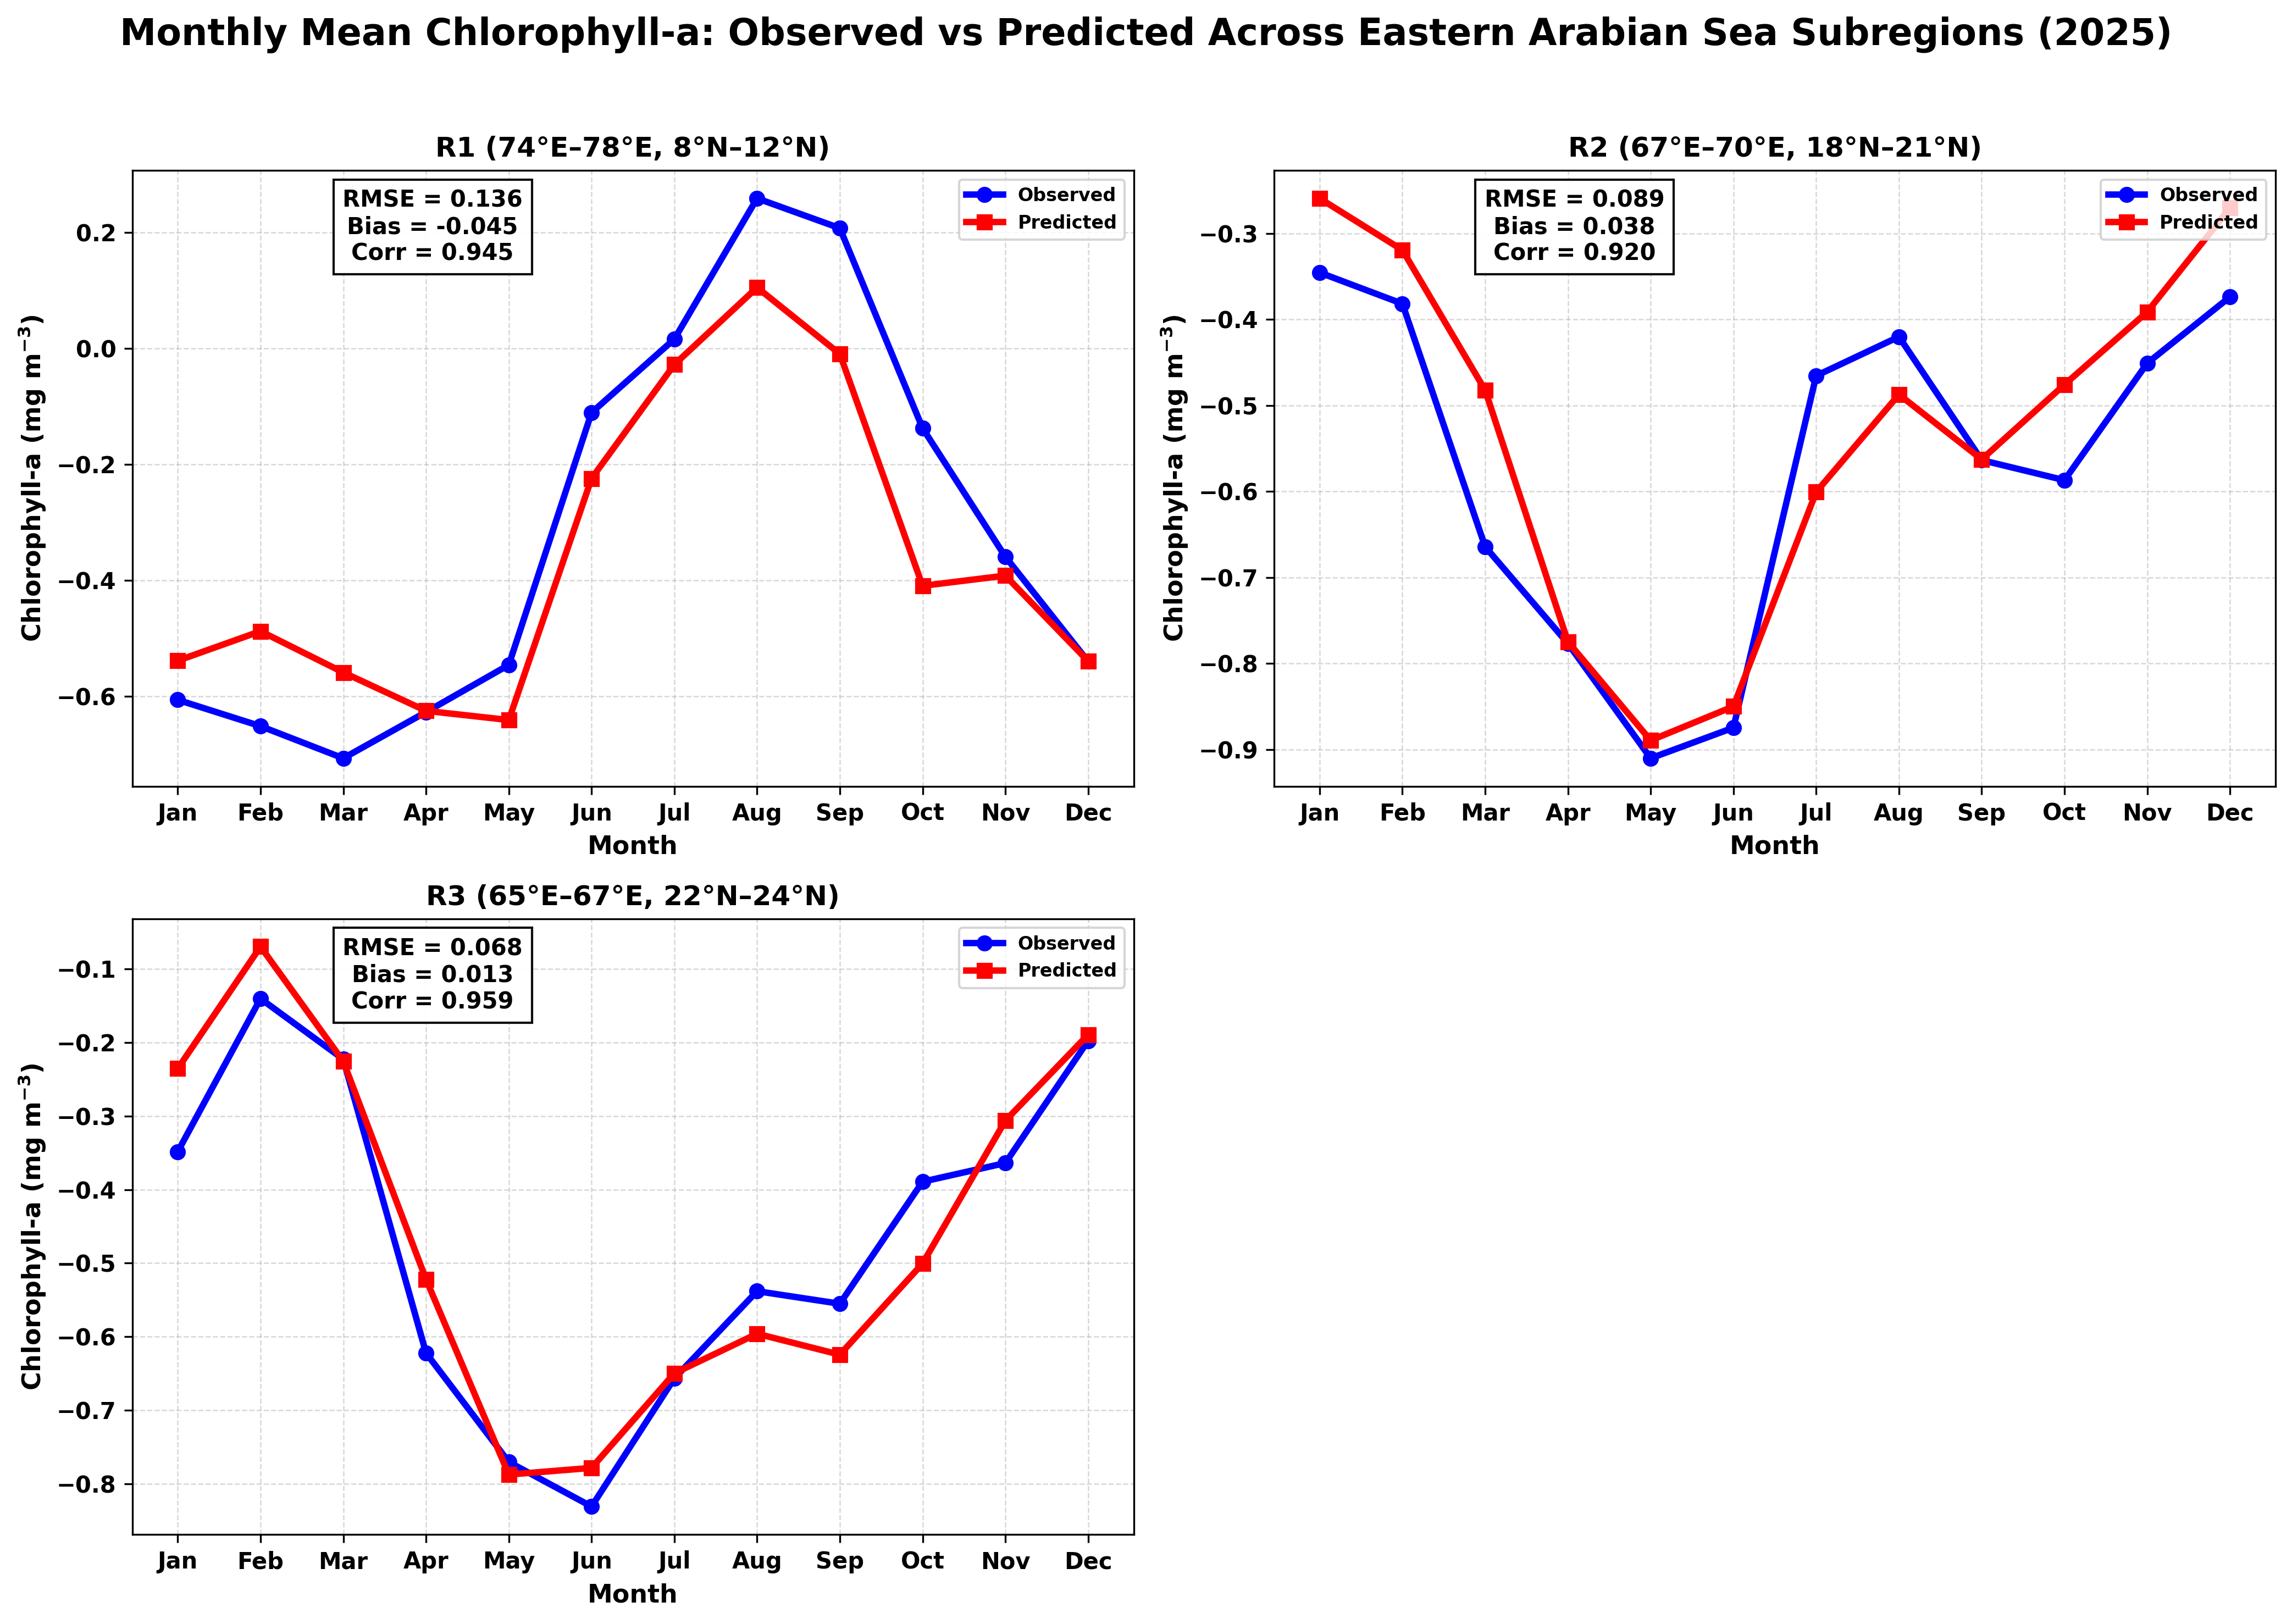

In [27]:
# logged
# ==========================================================
# Regional Monthly Chl-a Comparison
# Layout:
#
# R1   R2
# R3   R4
# R5   R6
#    R7
#
# ==========================================================

import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import mean_squared_error

# ==========================================================
# Subregions (Eastern Arabian Sea)
# ==========================================================

regions = {

    "R1 (74°E–78°E, 8°N–12°N)":
        [74.0, 78.0, 8.0, 12.0],

    "R2 (67°E–70°E, 18°N–21°N)":
        [67.0, 70.0, 18.0, 21.0],
    
     "R3 (65°E–67°E, 22°N–24°N)":
        [65.0, 67.0, 22.0, 24.0],
}

# ==========================================================
# Month Labels
# ==========================================================

months = [
    "Jan","Feb","Mar","Apr",
    "May","Jun","Jul","Aug",
    "Sep","Oct","Nov","Dec"
]

# ==========================================================
# Create Figure Layout
# ==========================================================

fig, axes = plt.subplots(
    2,
    2,
    figsize=(14, 10),
    dpi=300
)

axes = axes.flatten()

# Remove bottom-right panel
fig.delaxes(axes[3])

# Use only 3 axes:
# R1  R2
# R3
axes = [axes[0], axes[1], axes[2]]


# ==========================================================
# Loop Through Regions
# ==========================================================

for ax, (region_name, box) in zip(axes, regions.items()):

    lon1, lon2, lat1, lat2 = box

    # ------------------------------------------------------
    # Regional subset
    # ------------------------------------------------------

    ds_reg = ds_2025.sel(
        longitude=slice(lon1, lon2),
        latitude=slice(lat1, lat2)
    )

    # ------------------------------------------------------
    # Monthly Regional Means
    # ------------------------------------------------------

    obs_monthly = np.log10(
        ds_reg["chlor_a"]
        .mean(
            dim=["latitude", "longitude"],
            skipna=True
        )
        .values
    )

    pred_monthly = np.log10(
        ds_reg["chlor_a_pred"]
        .mean(
            dim=["latitude", "longitude"],
            skipna=True
        )
        .values
    )

    # ------------------------------------------------------
    # Metrics
    # ------------------------------------------------------

    valid = (
        np.isfinite(obs_monthly)
        &
        np.isfinite(pred_monthly)
    )

    obs_valid = obs_monthly[valid]
    pred_valid = pred_monthly[valid]

    rmse = np.sqrt(
        mean_squared_error(
            obs_valid,
            pred_valid
        )
    )

    bias = np.mean(
        pred_valid - obs_valid
    )

    corr = np.corrcoef(
        obs_valid,
        pred_valid
    )[0, 1]

    # ------------------------------------------------------
    # Observed
    # ------------------------------------------------------

    ax.plot(
        months,
        obs_monthly,
        color="blue",
        linewidth=2.8,
        marker="o",
        markersize=6,
        label="Observed"
    )

    # ------------------------------------------------------
    # Predicted
    # ------------------------------------------------------

    ax.plot(
        months,
        pred_monthly,
        color="red",
        linewidth=2.8,
        marker="s",
        markersize=6,
        label="Predicted"
    )

    # ------------------------------------------------------
    # Statistics Box
    # ------------------------------------------------------

    metric_text = (
        f"RMSE = {rmse:.3f}\n"
        f"Bias = {bias:.3f}\n"
        f"Corr = {corr:.3f}"
    )

    ax.text(
        0.30,
        0.97,
        metric_text,
        transform=ax.transAxes,
        fontsize=10,
        fontweight="bold",
        va="top",
        ha="center",
        bbox=dict(
            facecolor="white",
            edgecolor="black",
            alpha=0.95
        )
    )

    # ------------------------------------------------------
    # Titles
    # ------------------------------------------------------

    ax.set_title(
        region_name,
        fontsize=12,
        fontweight="bold"
    )

    # ------------------------------------------------------
    # Labels
    # ------------------------------------------------------

    ax.set_xlabel(
        "Month",
        fontsize=11,
        fontweight="bold"
    )

    ax.set_ylabel(
        r"Chlorophyll-a (mg m$^{-3}$)",
        fontsize=11,
        fontweight="bold"
    )

    # ------------------------------------------------------
    # Grid
    # ------------------------------------------------------

    ax.grid(
        linestyle="--",
        linewidth=0.6,
        alpha=0.5
    )

    # ------------------------------------------------------
    # Tick Formatting
    # ------------------------------------------------------

    ax.tick_params(
        axis='both',
        labelsize=10
    )

    for tick in ax.get_xticklabels():
        tick.set_fontweight("bold")

    for tick in ax.get_yticklabels():
        tick.set_fontweight("bold")

    # ------------------------------------------------------
    # Legend
    # ------------------------------------------------------

    ax.legend(
        loc="upper right",
        prop={
            "weight": "bold",
            "size": 8
        }
    )

# ==========================================================
# Global Figure Title
# ==========================================================

fig.suptitle(
    "Monthly Mean Chlorophyll-a: Observed vs Predicted Across Eastern Arabian Sea Subregions (2025)",
    fontsize=16,
    fontweight="bold",
    y=0.98
)

plt.tight_layout(
    rect=[0, 0, 1, 0.96]
)

plt.show()